<a href="https://colab.research.google.com/github/vinicuervo/Calculo-Numerico/blob/main/Atividade_19_10_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###**Atividade 19/10/2026**
###Vinicius Cruz Cuervo - 185337

Tabela de Iterações:
 k     x(k)     y(k)      z(k)  Erro Infinito
 0 0.000000 0.000000  0.000000            NaN
 1 0.600000 2.054545 -0.914545       2.054545
 2 0.988364 2.006711 -0.997002       0.388364
 3 1.000071 2.000279 -0.999986       0.011708
 4 1.000025 2.000004 -1.000005       0.000276
 5 1.000001 2.000000 -1.000000       0.000024
 6 1.000000 2.000000 -1.000000       0.000001


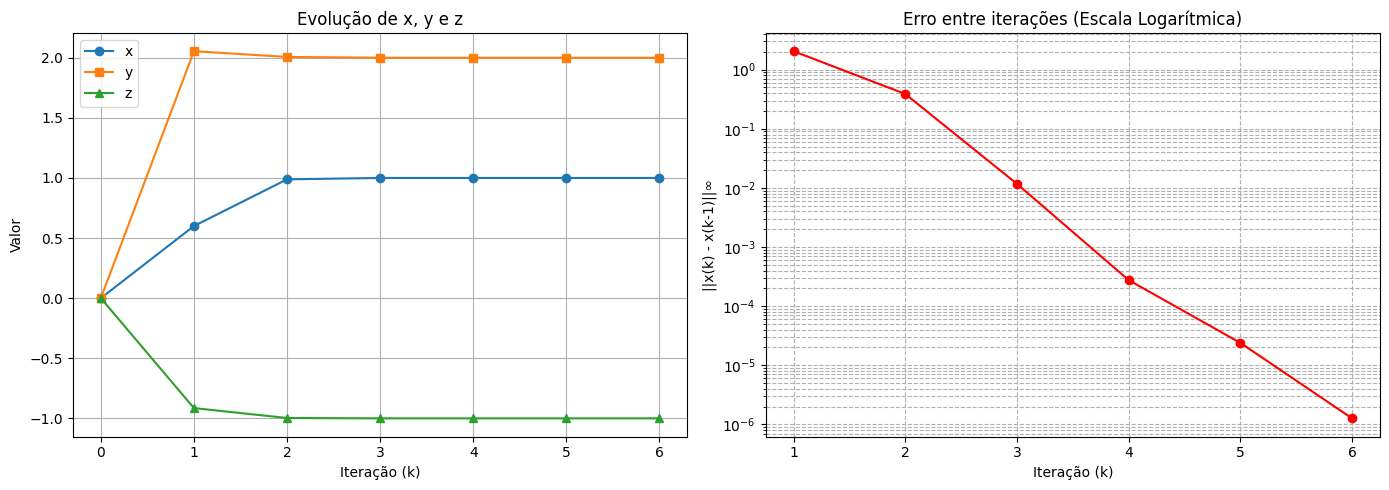

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Condições Iniciais
x, y, z = 0.0, 0.0, 0.0
tolerancia = 1e-5
erro = float('inf')
k = 0
resultados = [(k, x, y, z, None)]

# Iterações de Gauss-Seidel
while erro >= tolerancia:
    x_old, y_old, z_old = x, y, z

    # Fórmulas iterativas
    x = (6 + y_old - 2 * z_old) / 10
    y = (22 + x + z_old) / 11
    z = (-10 - 2 * x + y) / 10

    # Cálculo do erro máximo (norma infinito)
    erro = max(abs(x - x_old), abs(y - y_old), abs(z - z_old))
    k += 1
    resultados.append((k, x, y, z, erro))

# Organização em Tabela
df = pd.DataFrame(resultados, columns=["k", "x(k)", "y(k)", "z(k)", "Erro Infinito"])
print("Tabela de Iterações:")
print(df.to_string(index=False))

# Gráficos
iteracoes = [r[0] for r in resultados]
x_vals = [r[1] for r in resultados]
y_vals = [r[2] for r in resultados]
z_vals = [r[3] for r in resultados]
erros = [r[4] for r in resultados[1:]] # Erro começa em k=1

plt.figure(figsize=(14, 5))

# Gráfico: Evolução das variáveis
plt.subplot(1, 2, 1)
plt.plot(iteracoes, x_vals, marker='o', label='x')
plt.plot(iteracoes, y_vals, marker='s', label='y')
plt.plot(iteracoes, z_vals, marker='^', label='z')
plt.title("Evolução de x, y e z")
plt.xlabel("Iteração (k)")
plt.ylabel("Valor")
plt.legend()
plt.grid(True)

# Gráfico: Erro em escala logarítmica
plt.subplot(1, 2, 2)
plt.plot(iteracoes[1:], erros, marker='o', color='red')
plt.yscale('log')
plt.title("Erro entre iterações (Escala Logarítmica)")
plt.xlabel("Iteração (k)")
plt.ylabel("||x(k) - x(k-1)||∞")
plt.grid(True, which="both", ls="--")

plt.tight_layout()
plt.show()